Identifikasi dataset:

Jenis Klasifikasi: Multiclass Classification.
- Independent Variables: Island, bill_length_mm, bill_depth_mm, flipper_length_mm, body_mass_g, dan sex.
- Dependent Variable: species.
- Jumlah Independent Variables: 6 fitur jika semua fitur tersebut digunakan.
- Jumlah Dependent Variables: 1 target.
- Jumlah Kategori Target: 3 kategori.
- Kategori 1: Adelie.
- Kategori 2: Chinstrap.
- Kategori 3: Gentoo.

Penjelasan variabel:

1. Island: Menunjukkan pulau tempat penguin ditemukan.
2. bill_length_mm: Menunjukkan panjang paruh penguin dalam milimeter.
3. bill_depth_mm: Menunjukkan kedalaman paruh penguin dalam milimeter.
4. flipper_length_mm: Menunjukkan panjang sirip penguin.
5. body_mass_g: Menunjukkan berat badan penguin dalam gram.
6. sex: Menunjukkan jenis kelamin penguin.
7. species: Menunjukkan spesies penguin dan menjadi target klasifikasi.

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline          

In [14]:
df = pd.read_csv("penguins_size.csv")

In [15]:
print("=== IDENTIFIKASI DATASET PENGUIN ===")

print("\nInformasi Dataset:")
df.info()

print("\nJumlah Baris dan Kolom:")
print(df.shape)

print("\nNama Kolom:")
print(df.columns.tolist())

print("\nLima Data Pertama:")
print(df.head())

=== IDENTIFIKASI DATASET PENGUIN ===

Informasi Dataset:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   culmen_length_mm   342 non-null    float64
 3   culmen_depth_mm    342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                334 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB

Jumlah Baris dan Kolom:
(344, 7)

Nama Kolom:
['species', 'island', 'culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

Lima Data Pertama:
  species     island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  \
0  Adelie  Torgersen              39.1             18.7              181.0   
1  Adelie  Torgersen              39.5    

In [16]:
target = "species"

X = df.drop(columns=[target])
y = df[target]

print("\nIndependent Variables:")
print(X.columns.tolist())

print("\nDependent Variable:")
print(target)

print("\nJumlah Independent Variables:", X.shape[1])
print("Jumlah Dependent Variables:", 1)

print("\nJumlah Kategori Target:")
print(y.nunique())

print("\nDistribusi Target:")
print(y.value_counts())

print("\nIdentifikasi Klasifikasi:")
if y.nunique() > 2:
    print("Multiclass Classification")
else:
    print("Bukan Multiclass Classification")


Independent Variables:
['island', 'culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex']

Dependent Variable:
species

Jumlah Independent Variables: 6
Jumlah Dependent Variables: 1

Jumlah Kategori Target:
3

Distribusi Target:
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

Identifikasi Klasifikasi:
Multiclass Classification



=== EXPLORATORY DATA ANALYSIS (EDA) ===

Statistik Deskriptif:
       species  island  culmen_length_mm  culmen_depth_mm  flipper_length_mm  \
count      344     344        342.000000       342.000000         342.000000   
unique       3       3               NaN              NaN                NaN   
top     Adelie  Biscoe               NaN              NaN                NaN   
freq       152     168               NaN              NaN                NaN   
mean       NaN     NaN         43.921930        17.151170         200.915205   
std        NaN     NaN          5.459584         1.974793          14.061714   
min        NaN     NaN         32.100000        13.100000         172.000000   
25%        NaN     NaN         39.225000        15.600000         190.000000   
50%        NaN     NaN         44.450000        17.300000         197.000000   
75%        NaN     NaN         48.500000        18.700000         213.000000   
max        NaN     NaN         59.600000        21.50000

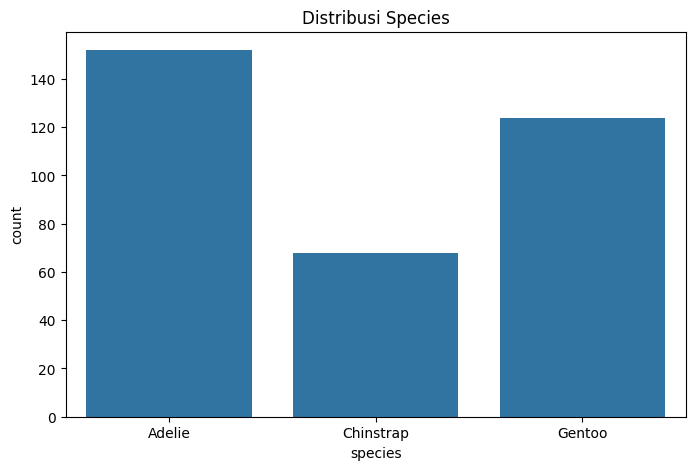

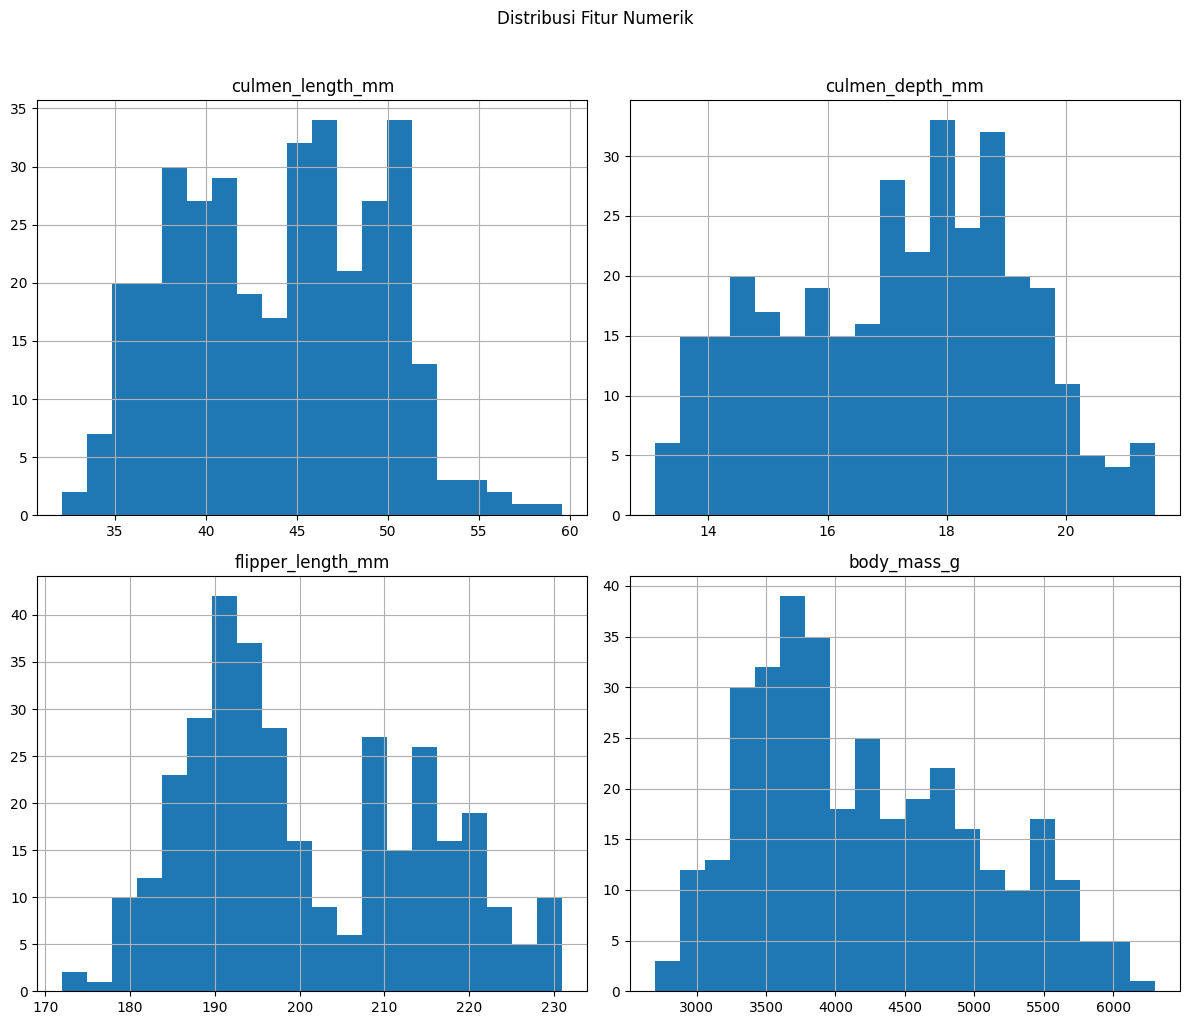

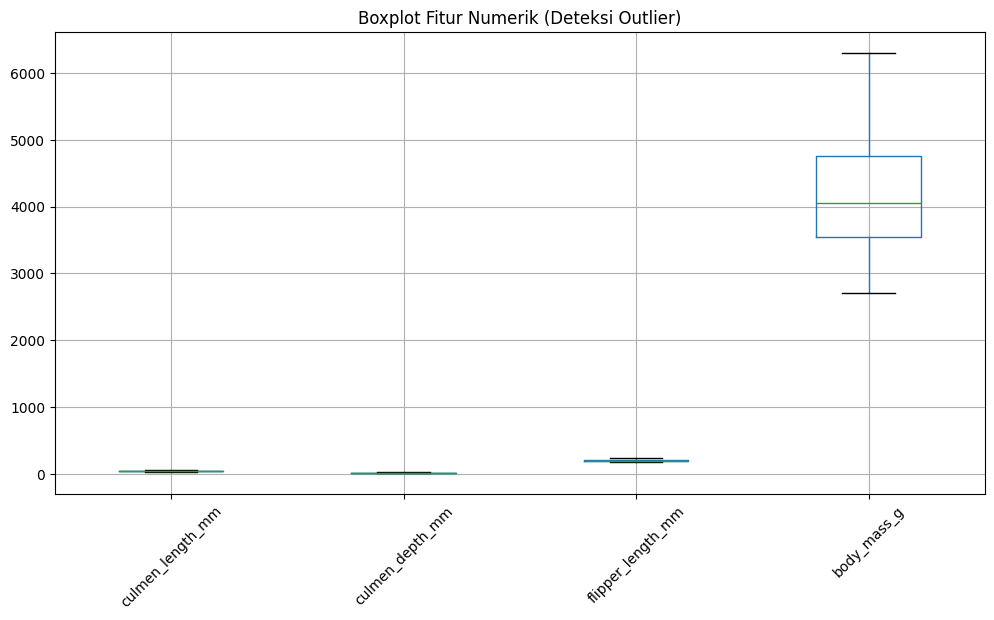

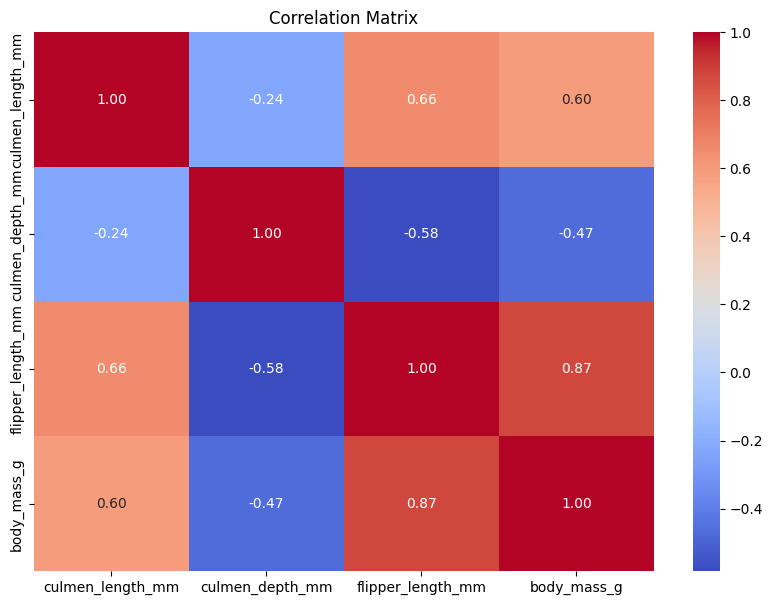

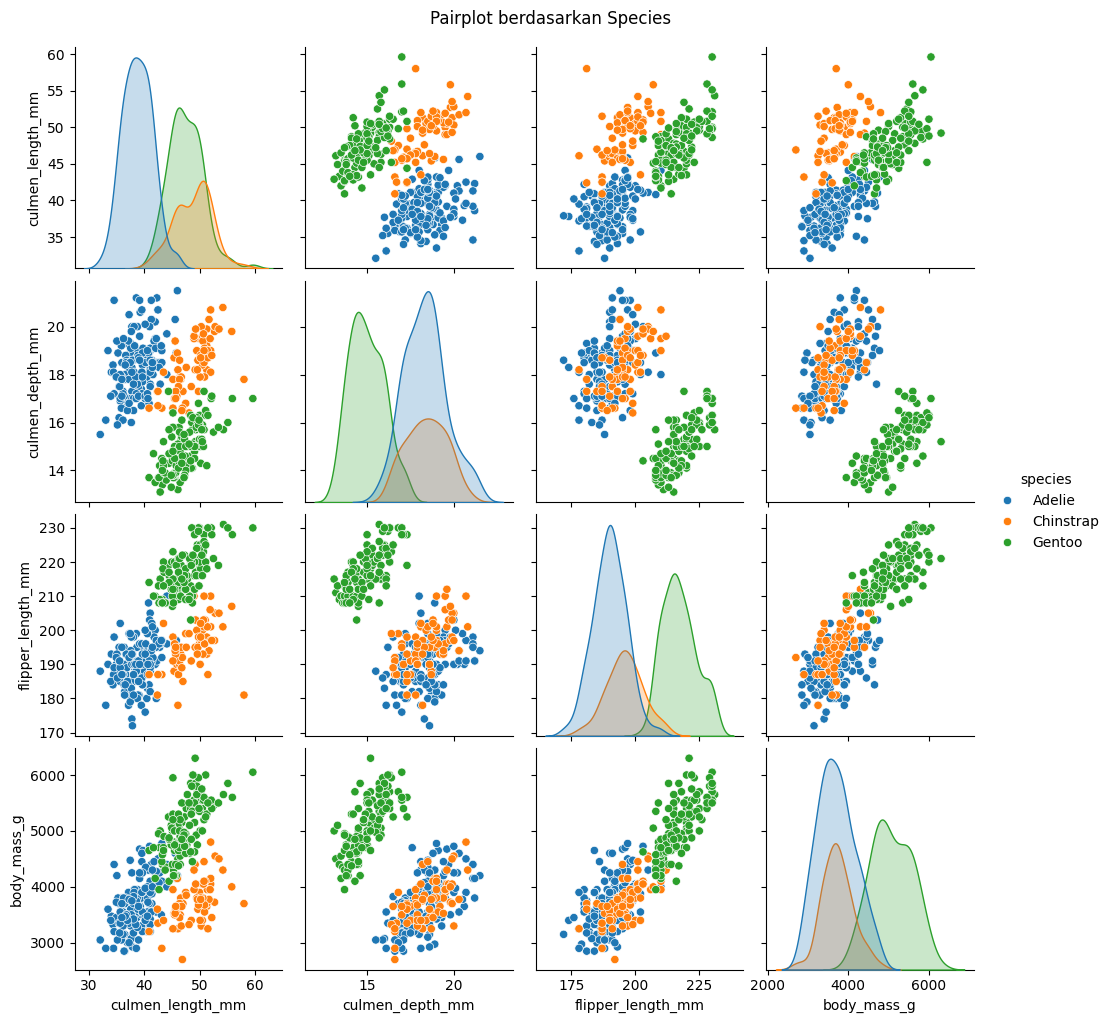

In [17]:
print("\n=== EXPLORATORY DATA ANALYSIS (EDA) ===")

# Statistik Deskriptif
print("\nStatistik Deskriptif:")
print(df.describe(include="all"))

# Cek Missing Value
print("\nMissing Values:")
print(df.isnull().sum())

# Cek Data Duplikat
print("\nJumlah Data Duplikat:", df.duplicated().sum())

# Distribusi Target
plt.figure(figsize=(8, 5))
sns.countplot(x=y)
plt.title("Distribusi Species")
plt.show()

# Histogram Fitur Numerik
numeric_cols = df.select_dtypes(include=np.number).columns
df[numeric_cols].hist(figsize=(12, 10), bins=20)
plt.suptitle("Distribusi Fitur Numerik", y=1.02)
plt.tight_layout()
plt.show()

# Boxplot Fitur Numerik
plt.figure(figsize=(12, 6))
df[numeric_cols].boxplot()
plt.title("Boxplot Fitur Numerik (Deteksi Outlier)")
plt.xticks(rotation=45)
plt.show()

# Correlation Heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Matrix")
plt.show()

# Distribusi berdasarkan Species (Pairplot)
sns.pairplot(df, hue="species", diag_kind="kde")
plt.suptitle("Pairplot berdasarkan Species", y=1.02)
plt.show()

In [18]:
print("\n=== PREPROCESSING ===")

# Pisahkan kolom numerik dan kategorikal
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include="object").columns.tolist()

print("Fitur Numerik:", numeric_features)
print("Fitur Kategorikal:", categorical_features)

# Pipeline Preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))   # <-- sudah diperbaiki
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Encode Target
le = LabelEncoder()
y_encoded = le.fit_transform(y)

print("\nLabel Encoding Target:")
print(dict(zip(le.classes_, le.transform(le.classes_))))

# Split Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.2,
    random_state=42,
    stratify=y_encoded
)

print(f"\nUkuran Train: {X_train.shape}")
print(f"Ukuran Test : {X_test.shape}")

# Fit Transform
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("\nPreprocessing selesai!")
print("- Missing values sudah di-handle")
print("- Fitur numerik sudah di-scale")
print("- Fitur kategorikal sudah di-OneHotEncode")
print("- Target sudah di-encode")
print("- Data sudah di-split (80:20)")


=== PREPROCESSING ===
Fitur Numerik: ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']
Fitur Kategorikal: ['island', 'sex']

Label Encoding Target:
{'Adelie': np.int64(0), 'Chinstrap': np.int64(1), 'Gentoo': np.int64(2)}

Ukuran Train: (275, 6)
Ukuran Test : (69, 6)

Preprocessing selesai!
- Missing values sudah di-handle
- Fitur numerik sudah di-scale
- Fitur kategorikal sudah di-OneHotEncode
- Target sudah di-encode
- Data sudah di-split (80:20)


C:\Users\surya rian\AppData\Local\Temp\ipykernel_4996\1715374469.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = X.select_dtypes(include="object").columns.tolist()


Penjelasan dataset: Palmer Penguins merupakan dataset yang berisi informasi mengenai tiga spesies penguin yang ditemukan di wilayah Kepulauan Palmer, Antartika.

Dataset ini memiliki informasi mengenai karakteristik fisik penguin, seperti panjang paruh, kedalaman paruh, panjang sirip, berat badan, jenis kelamin, dan lokasi pengamatan.